In [29]:
import pandas as pd
import numpy as np

df = pd.read_csv('student_grade_ses_dataset.csv')
df.head()

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,6/3/25,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2/5/25,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,21/3/25,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,30/3/25,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,6/5/25,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


## Drop duplicates

In [30]:
# Confirm duplicated student_ids are duplicate rows

# 1. Rows that share the same 'id'
id_dups = df[df.duplicated(subset=['student_id'], keep=False)]

# 2. Rows that share the same 'id' AND are identical across ALL columns
full_dups = df[df.duplicated(subset=['student_id'], keep=False) & df.duplicated(keep=False)]

print(f"Total rows with duplicate IDs: {len(id_dups)}")
print(f"Rows with duplicate IDs that are FULLY identical: {len(full_dups)}")
print(f"Rows with duplicate IDs that have DIFFERENCES: {len(id_dups) - len(full_dups)}")

df = df.drop_duplicates(subset=['student_id']) 

Total rows with duplicate IDs: 50
Rows with duplicate IDs that are FULLY identical: 50
Rows with duplicate IDs that have DIFFERENCES: 0


## Target and predictors

In [31]:
TARGET_COL = 'final_grade_pct'

# Heavily skewed income, so log-transform it.
df['log_income'] = np.log(df['annual_family_income_inr'])

CONTINUOUS_COLS = [
    'distance_to_school_km', 'study_hours_per_week', 'attendance_rate_pct',
    'previous_year_grade_pct', 'log_income',
]

# Integer-coded predictors; term types are specified in the GAM section.
DISCRETE_COLS = [
    'age', 'grade_level', 'family_size', 'num_siblings',
    'single_parent_household', 'has_internet_access',
    'has_computer_or_laptop', 'extra_tutoring', 'parental_involvement_score',
]

# Match the Project.ipynb predictor set.
CATEGORICAL_COLS = [
    'academic_year', 'gender', 'school_type', 'residence_type',
    'family_income_bracket', 'father_education_level', 'mother_education_level',
    'father_occupation', 'mother_occupation', 'scholarship_status',
]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [32]:
X = df[PREDICTOR_COLS]
Y = df[TARGET_COL]
print('X:', X.shape, ' Y:', Y.shape)

# Match Project.ipynb: stratified 85/15 split; use training data for CV only.
from sklearn.model_selection import train_test_split
TEST_SIZE = 0.15
SEED = 42
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=TEST_SIZE, stratify=df['grade_class'], random_state=SEED
)
print('train:', X_train.shape, ' test:', X_test.shape)

X: (12000, 24)  Y: (12000,)
train: (10200, 24)  test: (1800, 24)


## Impute Nan

In [33]:
medians = X_train[NUMERIC_COLS].median()
modes = X_train[CATEGORICAL_COLS].mode().iloc[0]

for X_part in (X_train, X_test):
    X_part[NUMERIC_COLS] = X_part[NUMERIC_COLS].fillna(medians)
    X_part[CATEGORICAL_COLS] = X_part[CATEGORICAL_COLS].fillna(modes)

assert X_train.notna().all().all() and X_test.notna().all().all()
print('train:', X_train.shape, ' test:', X_test.shape)

train: (10200, 24)  test: (1800, 24)


18 components explain 81.8% of the variation


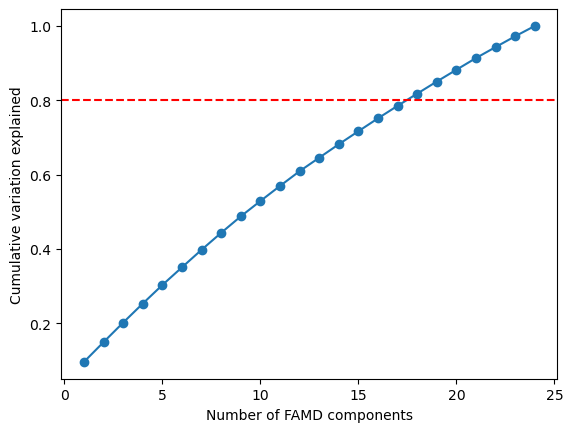

In [41]:
import pandas as pd
import prince

# Fit all available components, then keep enough to explain 80% of the variation
famd = prince.FAMD(n_components=len(PREDICTOR_COLS), random_state=42).fit(X_train)

eigenvalues = np.array(famd.eigenvalues_)
cumulative_variance = np.cumsum(eigenvalues) / eigenvalues.sum()
N_COMPONENTS = np.argmax(cumulative_variance >= 0.80) + 1
print(f'{N_COMPONENTS} components explain {cumulative_variance[N_COMPONENTS - 1]:.1%} of the variation')

import matplotlib.pyplot as plt
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axhline(0.80, color='red', linestyle='--')
plt.xlabel('Number of FAMD components')
plt.ylabel('Cumulative variation explained')
plt.show()

In [42]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# FAMD coordinates for the training predictors
Z = famd.row_coordinates(X_train).iloc[:, :N_COMPONENTS]

for k in range(2, 9):
    labels = KMeans(n_clusters=k, random_state=42, n_init="auto").fit_predict(Z)
    score = silhouette_score(Z, labels)
    print(f"k={k}: silhouette={score:.3f}")

k=2: silhouette=0.091
k=3: silhouette=0.094
k=4: silhouette=0.080
k=5: silhouette=0.067
k=6: silhouette=0.078
k=7: silhouette=0.080
k=8: silhouette=0.092


In [52]:
# Profile the 3-cluster solution and compare outcomes
profile = X_train.copy()
profile['cluster'] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(Z)
profile['final_grade_pct'] = Y_train

numeric_summary = profile.groupby('cluster')[NUMERIC_COLS + ['final_grade_pct']].mean().T
categorical_summary = pd.concat([
    pd.crosstab(profile[col], profile['cluster'], normalize='columns').mul(100).rename(index=lambda level: f'{col}: {level}')
    for col in CATEGORICAL_COLS
])
cluster_profile_table = pd.concat([numeric_summary, categorical_summary])
cluster_profile_table.columns = [f'Cluster {c}' for c in cluster_profile_table.columns]
cluster_profile_table.index.name = 'Feature / category'
display(cluster_profile_table.round(1))

,Cluster 0,Cluster 1,Cluster 2
Feature / category,,,
distance_to_school_km,4.0,3.6,3.6
study_hours_per_week,13.2,16.0,10.5
attendance_rate_pct,84.0,88.2,87.4
previous_year_grade_pct,58.3,67.4,74.3
log_income,12.2,13.5,13.0
...,...,...,...
mother_occupation: Unemployed,18.4,7.6,0.0
mother_occupation: Unskilled Labor,12.5,5.8,0.0
scholarship_status: Full,11.4,2.1,0.0


### Exploratory interpretation

**What this analysis does:** FAMD compresses the mixed numeric and categorical predictors into components. K-means then groups students whose component scores are close. We retained 18 components to capture about 81.8% of the variation. Final grade was left out of the clustering and compared afterward.

**What we observed:** The three-cluster solution is very imbalanced: clusters 0 and 1 contain 5,660 and 4,538 students, while cluster 2 contains only 2. Those two students average 10 family members and 8 siblings, compared with 4.6 family members and 2.1 siblings in the larger clusters. These overlapping household-size features may be helping to isolate them. The two large groups also show a broad contrast: cluster 0 has lower averages for previous-year grade (58.3 vs. 67.4), study hours (13.2 vs. 16.0 per week), attendance (84.0% vs. 88.2%), internet access (40% vs. 60%), and final grade (63.1 vs. 71.7).

**What this means:** The analysis suggests a broad lower- and higher-performing pattern among the two large groups, but it does not find sharply separated student types. The low silhouette score (0.094) supports that caution. Cluster numbers are arbitrary labels, and these descriptive differences do not show that any feature causes higher or lower grades. Treat the result as an exploratory summary of patterns in this dataset, not as a reliable way to assign individual students to fixed categories.

### Check the household-size effect

To see whether the tiny cluster depends on household size, refit FAMD and K-means after removing both `family_size` and `num_siblings`. The tiny cluster disappeared: the new sizes are 3,547, 5,166, and 1,487. However, the silhouette score fell from 0.094 to 0.081, so the new groups are not more clearly separated. The next cell profiles these revised groups and compares their average final grades.

In [46]:
# Refit without the two overlapping household-size predictors
removed = ['family_size', 'num_siblings']
reduced_cols = [col for col in PREDICTOR_COLS if col not in removed]
famd_reduced = prince.FAMD(n_components=len(reduced_cols), random_state=42).fit(X_train[reduced_cols])
eigenvalues_reduced = np.array(famd_reduced.eigenvalues_)
cumvar_reduced = np.cumsum(eigenvalues_reduced) / eigenvalues_reduced.sum()
n_reduced = np.argmax(cumvar_reduced >= 0.80) + 1
Z_reduced = famd_reduced.row_coordinates(X_train[reduced_cols]).iloc[:, :n_reduced]
labels_reduced = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(Z_reduced)
print(f'Components retained: {n_reduced}')
print('Cluster sizes without family_size and num_siblings:')
print(pd.Series(labels_reduced).value_counts().sort_index())
print(f'Silhouette score: {silhouette_score(Z_reduced, labels_reduced):.3f}')

Components retained: 17
Cluster sizes without family_size and num_siblings:
0    3547
1    5166
2    1487
Name: count, dtype: int64
Silhouette score: 0.081


In [51]:
# Profile the revised clusters without the household-size features
profile_reduced = X_train[reduced_cols].copy()
profile_reduced['cluster'] = labels_reduced
profile_reduced['final_grade_pct'] = Y_train
numeric_reduced = [col for col in NUMERIC_COLS if col in reduced_cols]
numeric_summary = profile_reduced.groupby('cluster')[numeric_reduced + ['final_grade_pct']].mean().T
categorical_summary = pd.concat([
    pd.crosstab(profile_reduced[col], profile_reduced['cluster'], normalize='columns').mul(100).rename(index=lambda level: f'{col}: {level}')
    for col in CATEGORICAL_COLS
])
cluster_profile_table = pd.concat([numeric_summary, categorical_summary])
cluster_profile_table.columns = [f'Cluster {c}' for c in cluster_profile_table.columns]
cluster_profile_table.index.name = 'Feature / category'
display(cluster_profile_table.round(1))

,Cluster 0,Cluster 1,Cluster 2
Feature / category,,,
distance_to_school_km,4.0,3.7,3.9
study_hours_per_week,12.8,15.0,16.7
attendance_rate_pct,83.1,86.9,88.7
previous_year_grade_pct,56.9,63.7,70.4
log_income,12.0,13.0,14.2
...,...,...,...
mother_occupation: Unemployed,21.1,10.7,5.6
mother_occupation: Unskilled Labor,14.8,7.6,3.8
scholarship_status: Full,13.0,5.0,1.7
